# Validate linear summation (metamodel vs dynamic)

Compare offshore-driven **dynamic SnapWave** to the **reconstructed metamodel**
(spectral mode: WHACS partitions `0`–`3` per goal, wavespectra linear sum).

Bulk output is configured in the case JSON → `metamodel.reconstruction.variables`
(HyGloW name → wavespectra stat). Set `save_spectra: true` to cache summed spectra
for notebook 11.

Comparison uses `hs`, `tp`, `dir`, and `spr` when both datasets contain them
(`val.resolve_comparison_variables`).

**Prerequisites:** fitted models (06), dynamic run (08). Use `recompute=True` after refitting.

In [1]:
import matplotlib.pyplot as plt
import xarray as xr
from utils.config import SIMULATIONS, resolve
from utils.evaluation import validation as val
from utils.model import metamodel as mm

## Configuration

In [2]:
period = "2017"
offshore_name = "WHACS"
mda_n = 450  # must match a fitted mda_candidates entry
pca_variance = 0.99  # or 0.99, or {"hs": 0.99, etc}

# Site subset — isobath depth, mesh polygon, buoy id, or umbrella
sites = "buoy"  # e.g. "10m", "buoy", or a list of explicit site ids

# Metrics to compare (subset used when missing from either dataset)
compare_variables = ["hs", "tp", "dir", "spr"]

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"]) / f"Dynamic_Cases_{offshore_name}_{period}.nc"
)

print(f"period       : {period}")
print(f"mda_n        : {mda_n}")
print(f"sites        : {sites}")
print(f"compare vars : {compare_variables}")
print(f"dynamic path : {dynamic_path}")

period       : 2017
mda_n        : 450
sites        : buoy
compare vars : ['hs', 'tp', 'dir', 'spr']
dynamic path : /hyglowdata/NewSouthWales/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_2017.nc


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)
print(f"common model sites: {len(mm.common_model_sites())}")

common model sites: 3860


## 2 · Reconstruct metamodel (bulk)

In [4]:
metamodel = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)
metamodel

<xarray.Dataset> Size: 9MB
Dimensions:         (time: 8760, sites: 35)
Coordinates:
  * time            (time) datetime64[ns] 70kB 2017-01-01 ... 2017-12-31T23:0...
  * sites           (sites) <U22 3kB 'buoy_Sydney_Buoy' ... 'buoy_Merimbula2_...
    site_source     (sites) <U7 980B 'buoy' 'buoy' 'buoy' ... 'buoy' 'buoy'
    site_label      (sites) <U5 700B 'waves' 'waves' 'waves' ... 'waves' 'waves'
    site_depth      (sites) float64 280B -85.0 -75.0 -80.0 ... -13.09 -13.01
    site_longitude  (sites) float64 280B 151.4 151.0 152.9 ... 150.2 149.9 149.9
    site_latitude   (sites) float64 280B -33.77 -34.47 -31.82 ... -36.91 -36.91
Data variables:
    hs              (time, sites) float64 2MB 1.225 1.146 ... 0.8984 0.8966
    tp              (time, sites) float32 1MB 7.349 7.313 6.674 ... 6.278 6.278
    dir             (time, sites) float64 2MB 103.8 90.82 67.78 ... 108.8 109.1
    spr             (time, sites) float64 2MB 42.97 38.67 41.71 ... 39.17 39.17

## 3 · Load dynamic reference

In [5]:
dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids).load()
dynamic

<xarray.Dataset> Size: 5MB
Dimensions:         (time: 8760, sites: 35)
Coordinates:
  * time            (time) datetime64[ns] 70kB 2017-01-01 ... 2017-12-31T23:0...
  * sites           (sites) <U22 3kB 'buoy_Sydney_Buoy' ... 'buoy_Merimbula2_...
    site_source     (sites) <U7 980B 'buoy' 'buoy' 'buoy' ... 'buoy' 'buoy'
    site_label      (sites) <U5 700B 'waves' 'waves' 'waves' ... 'waves' 'waves'
    site_depth      (sites) float64 280B -85.0 -75.0 -80.0 ... -13.09 -13.01
    site_longitude  (sites) float64 280B 151.4 151.0 152.9 ... 150.2 149.9 149.9
    site_latitude   (sites) float64 280B -33.77 -34.47 -31.82 ... -36.91 -36.91
Data variables:
    hs              (time, sites) float32 1MB 1.197 1.184 ... 0.7887 0.7883
    tp              (time, sites) float32 1MB 6.84 6.84 6.84 ... 6.764 6.764
    dir             (time, sites) float32 1MB 79.42 72.99 74.18 ... 101.5 101.7
    spr             (time, sites) float32 1MB 43.37 42.36 37.11 ... 36.73 36.85
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

## 4 · Compare

In [6]:
variables = val.resolve_comparison_variables(
    metamodel,
    dynamic,
    variables=compare_variables,
)
print(f"Comparing: {variables}")

result = val.compare(
    metamodel,
    dynamic,
    variables=variables,
    estimate_label="Linear summation",
    reference_label="Dynamic SnapWave",
    pca_variance=pca_variance,
)
result.metrics

Comparing: ['hs', 'tp', 'dir', 'spr']


,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label
0,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,hs,Hs,8760,-0.011751,0.195888,0.916192,Linear summation,Dynamic SnapWave
1,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,tp,Tp,8760,-0.112003,1.206046,0.678254,Linear summation,Dynamic SnapWave
2,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,dir,Dir,8760,2.005015,20.083767,0.784895,Linear summation,Dynamic SnapWave
3,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,spr,Spr,8760,-1.418036,7.010037,0.378782,Linear summation,Dynamic SnapWave
4,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_PortKembla_Buoy,buoy,waves,hs,Hs,8760,-0.047087,0.203803,0.877793,Linear summation,Dynamic SnapWave
...,...,...,...,...,...,...,...,...,...,...,...,...
135,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Merimbula_Buoy,buoy,waves,spr,Spr,8760,1.452946,8.143102,-0.243479,Linear summation,Dynamic SnapWave
136,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Merimbula2_Buoy,buoy,waves,hs,Hs,8760,-0.050473,0.235117,0.561145,Linear summation,Dynamic SnapWave
137,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Merimbula2_Buoy,buoy,waves,tp,Tp,8760,-0.404756,1.772494,0.356957,Linear summation,Dynamic SnapWave
138,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Merimbula2_Buoy,buoy,waves,dir,Dir,8760,4.236294,28.499477,0.218861,Linear summation,Dynamic SnapWave


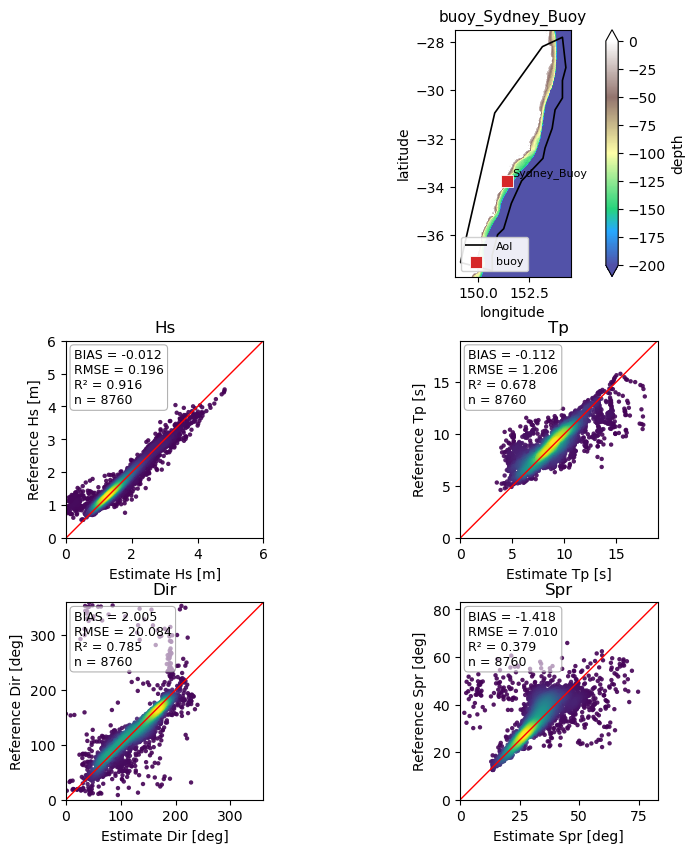

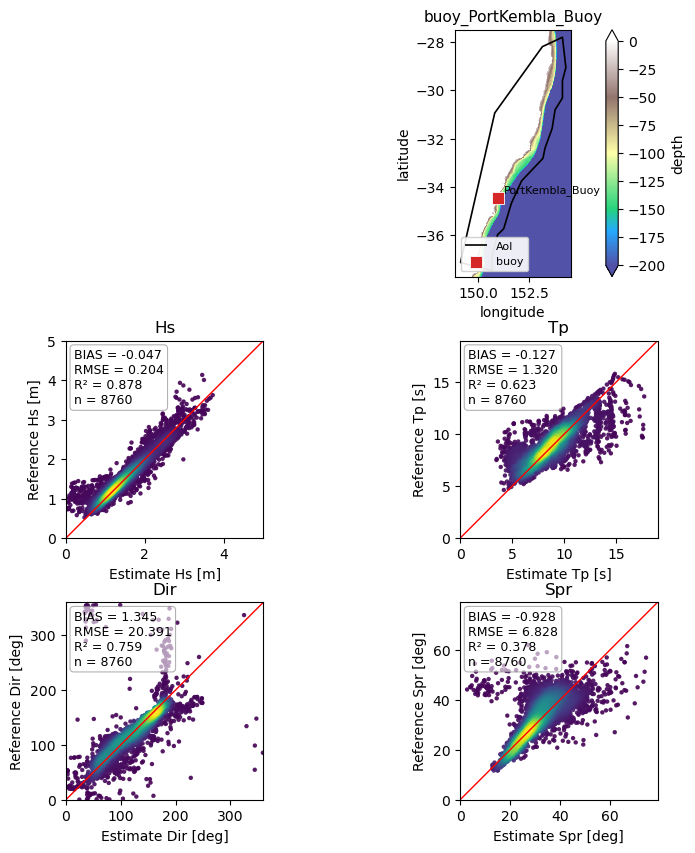

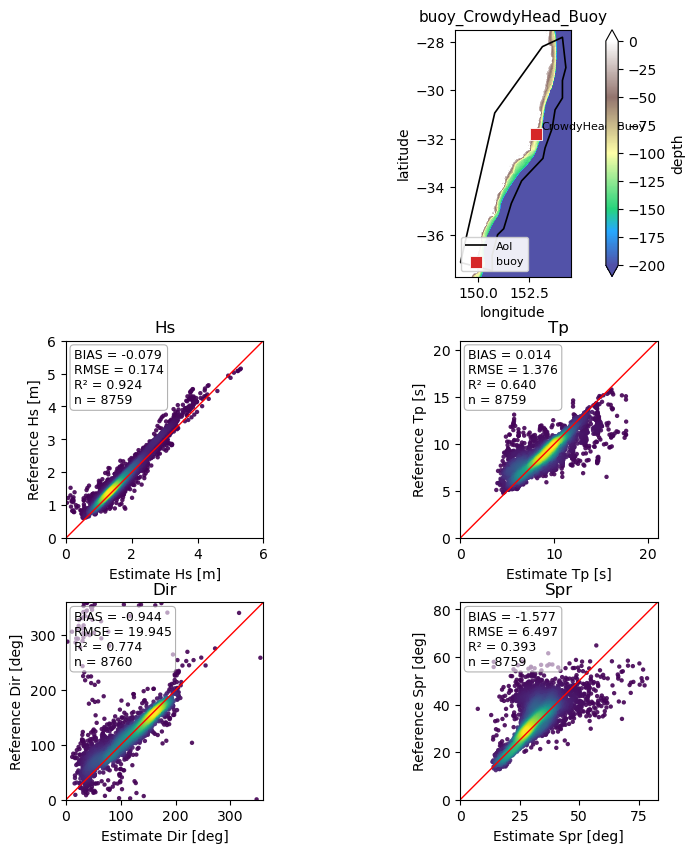

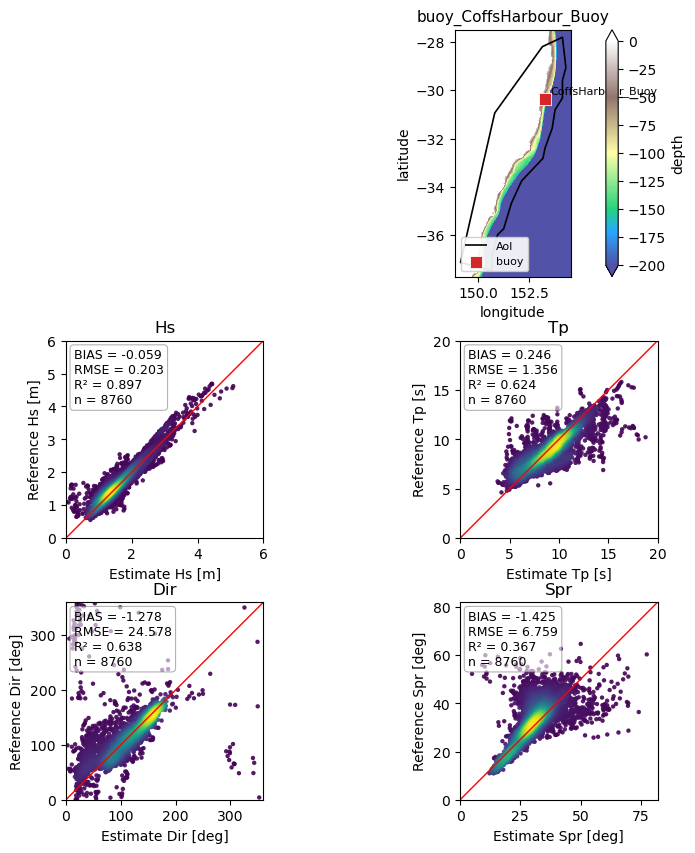

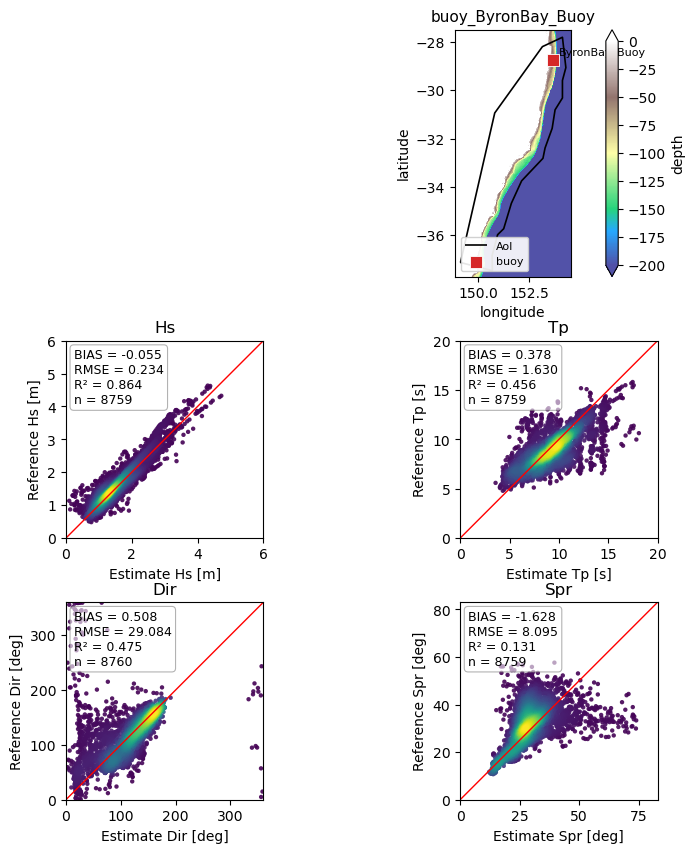

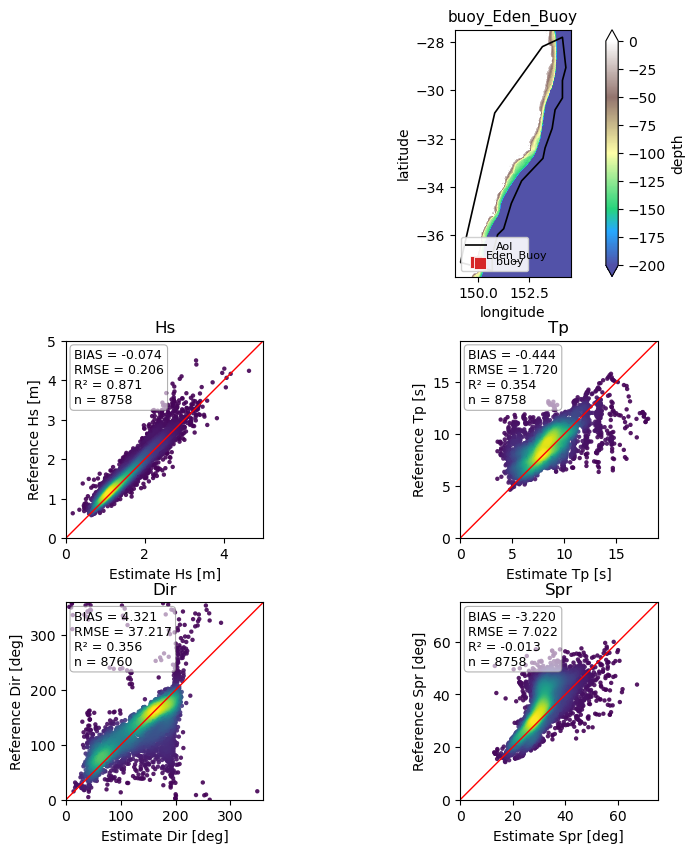

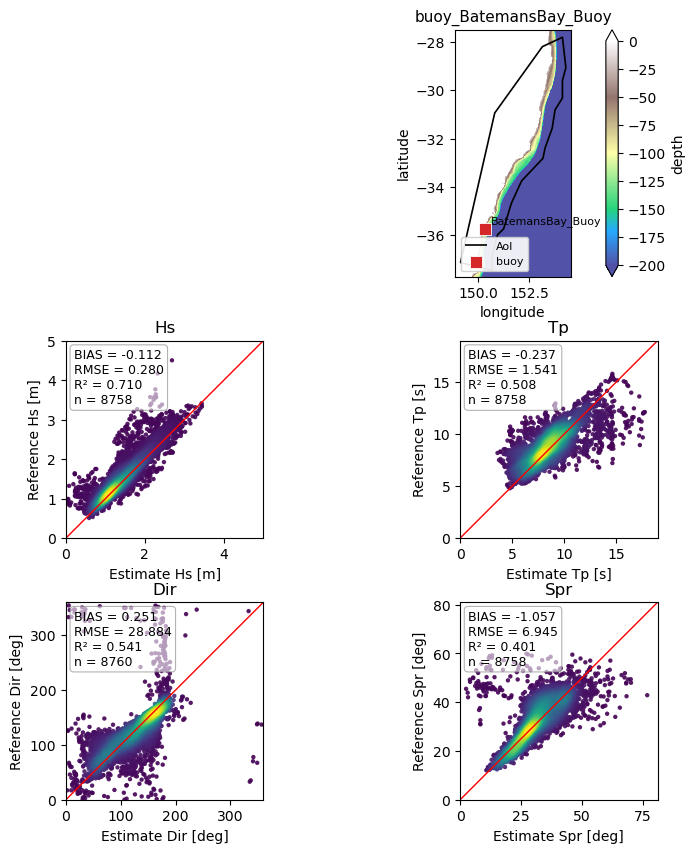

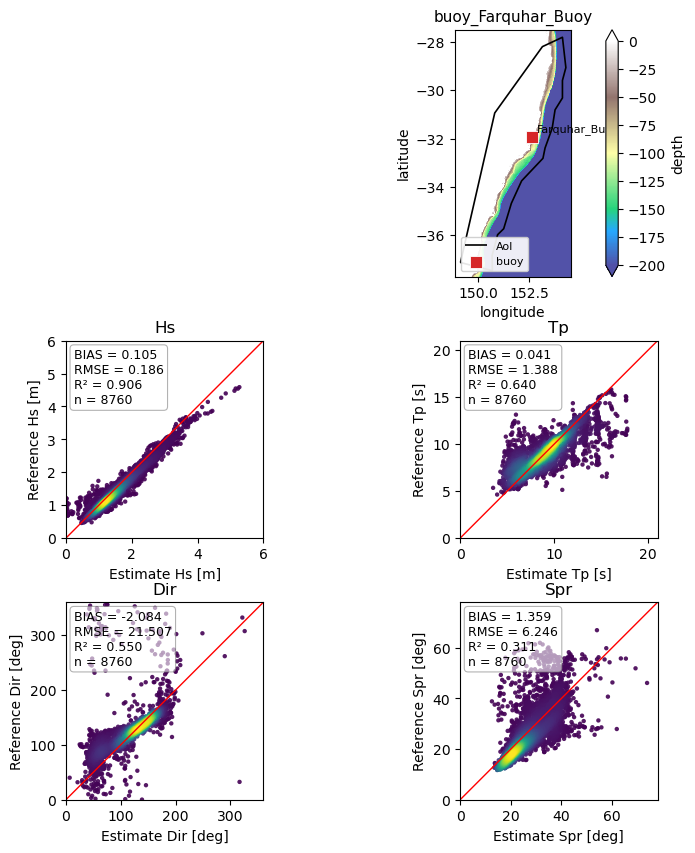

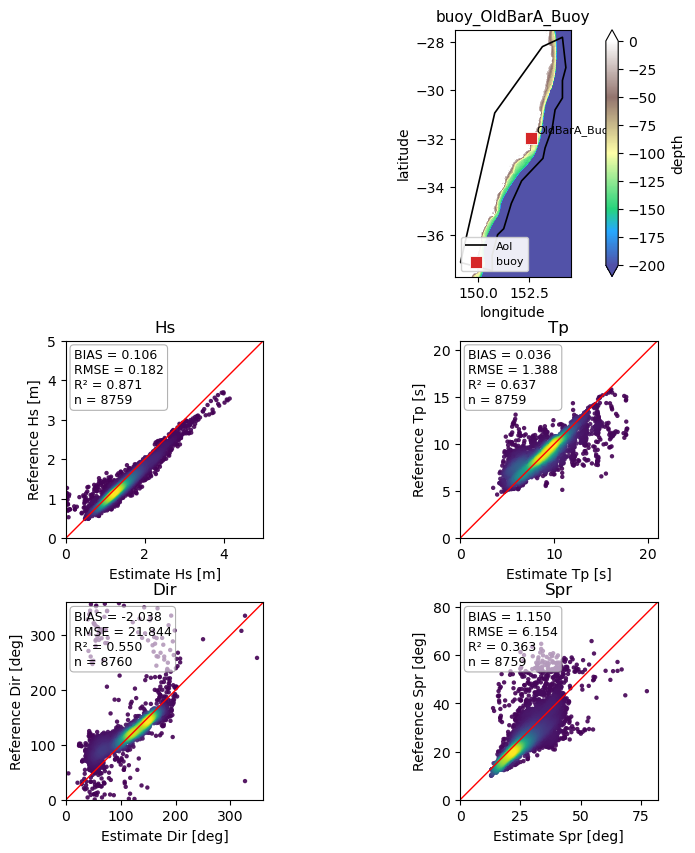

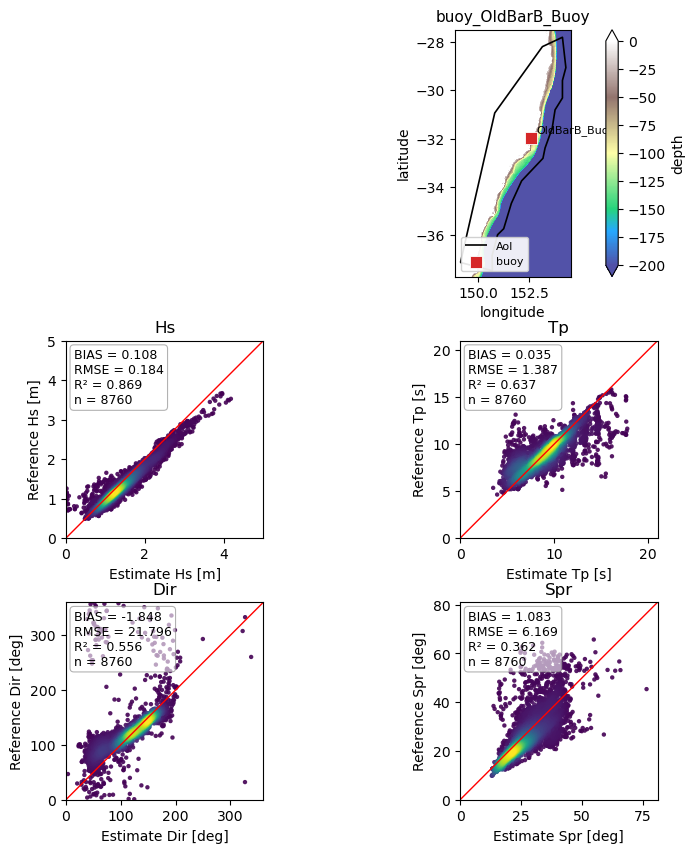

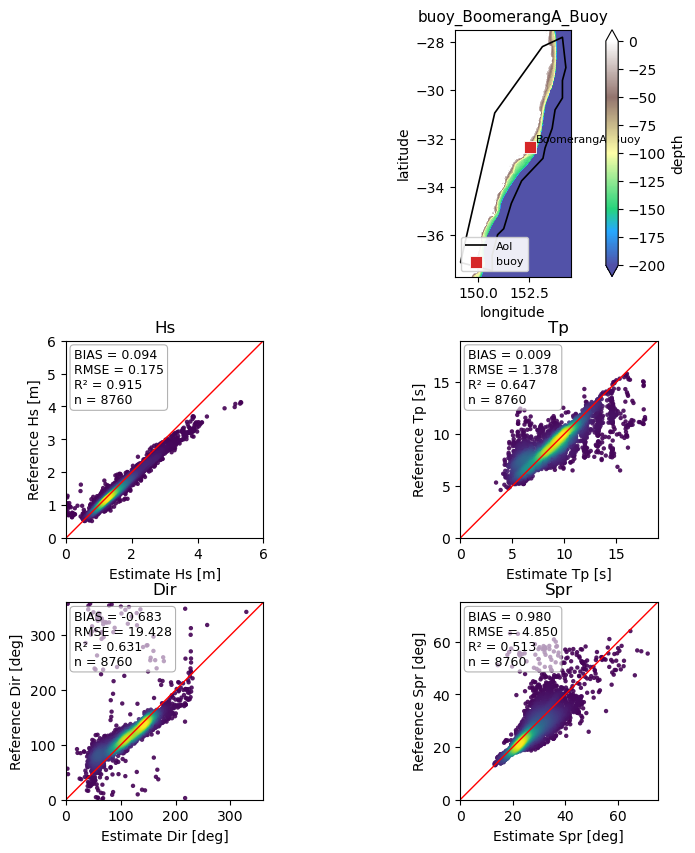

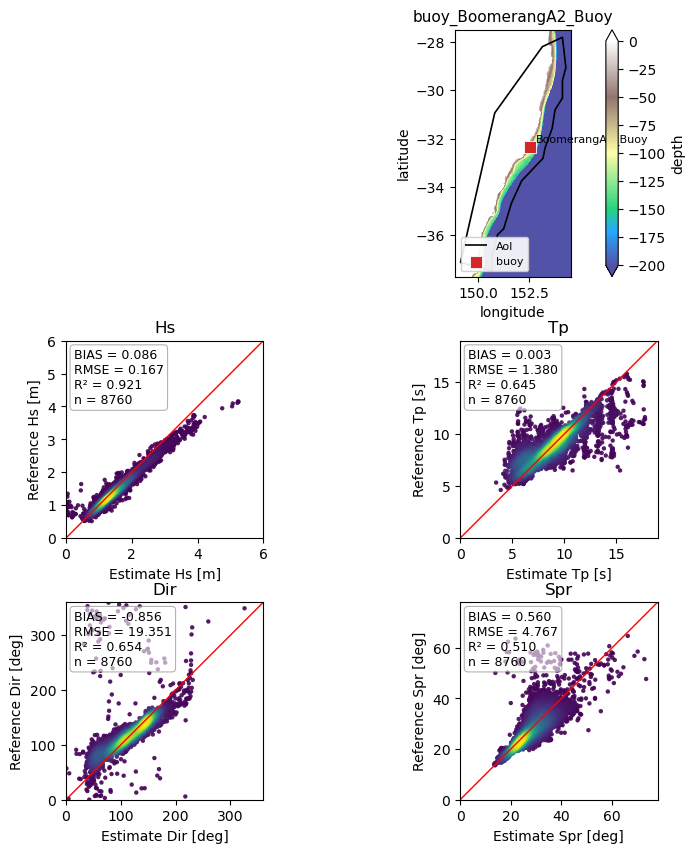

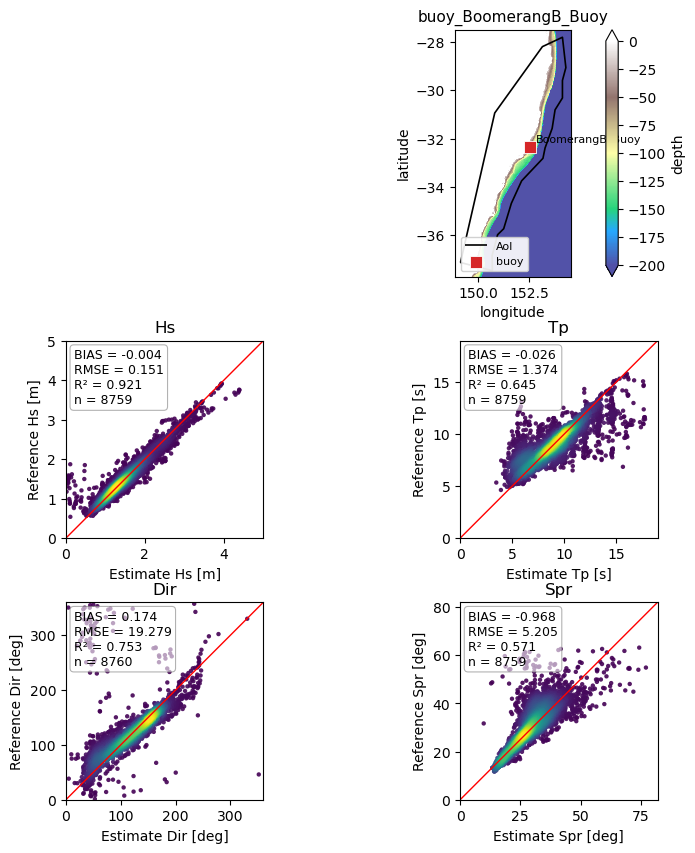

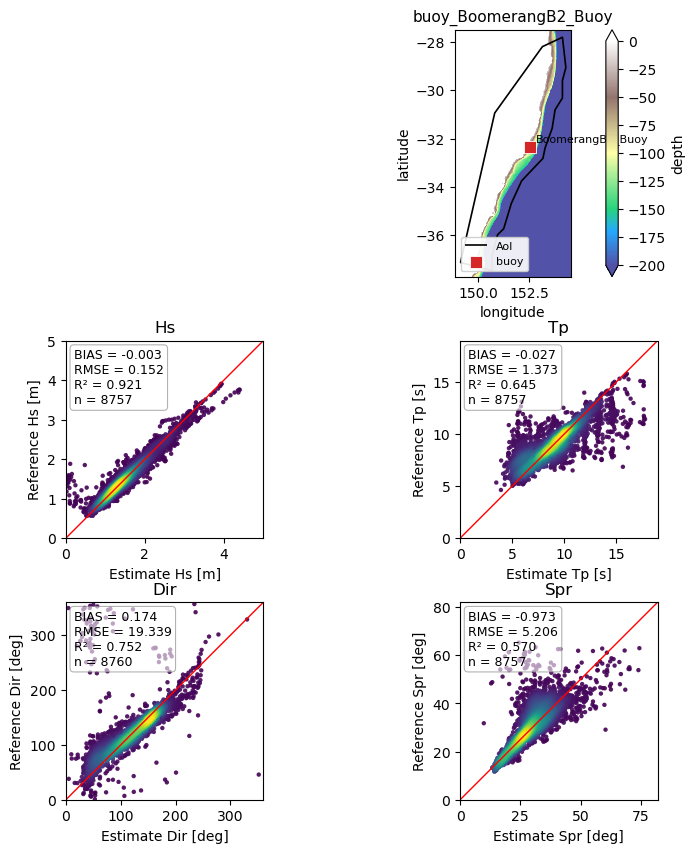

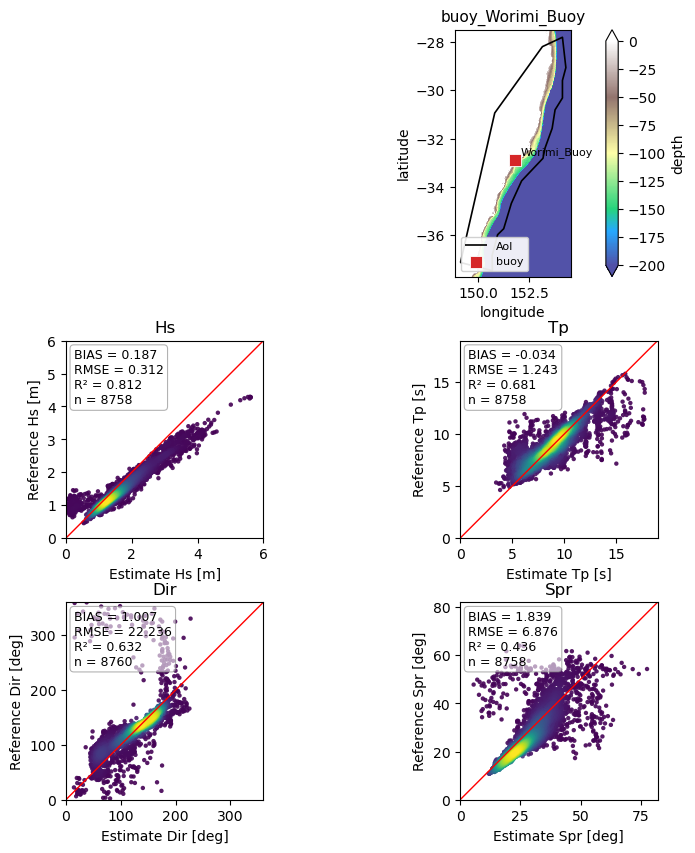

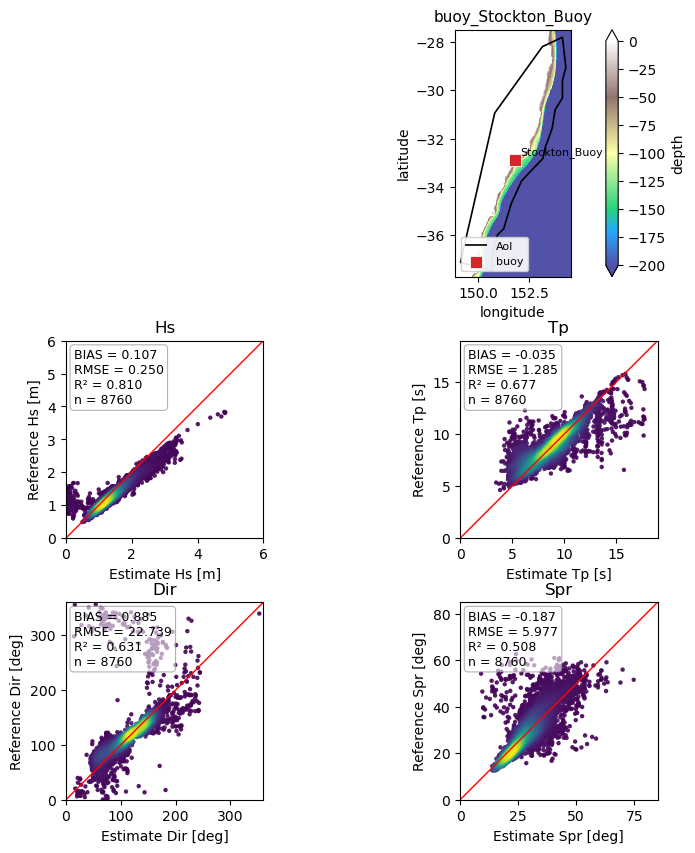

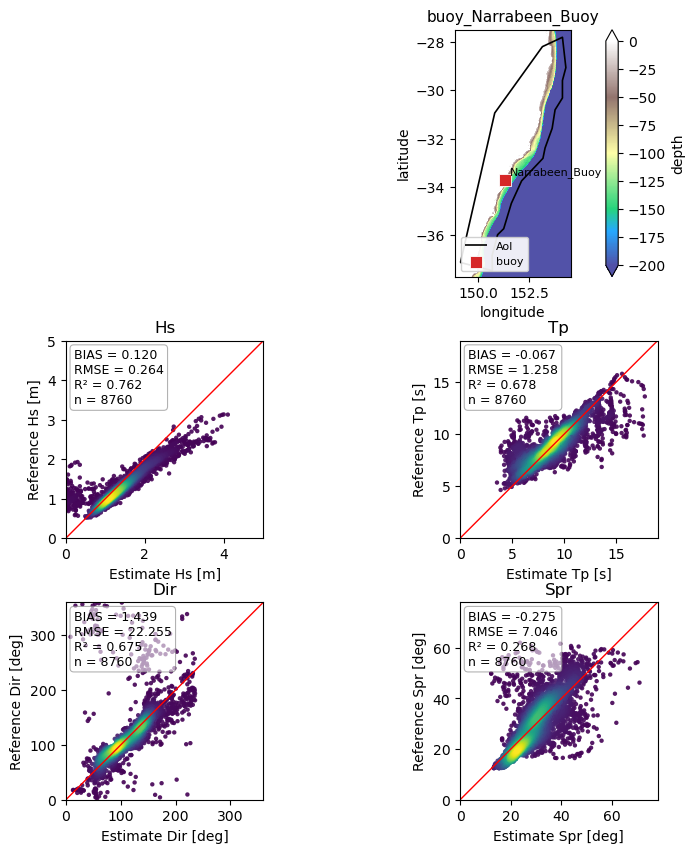

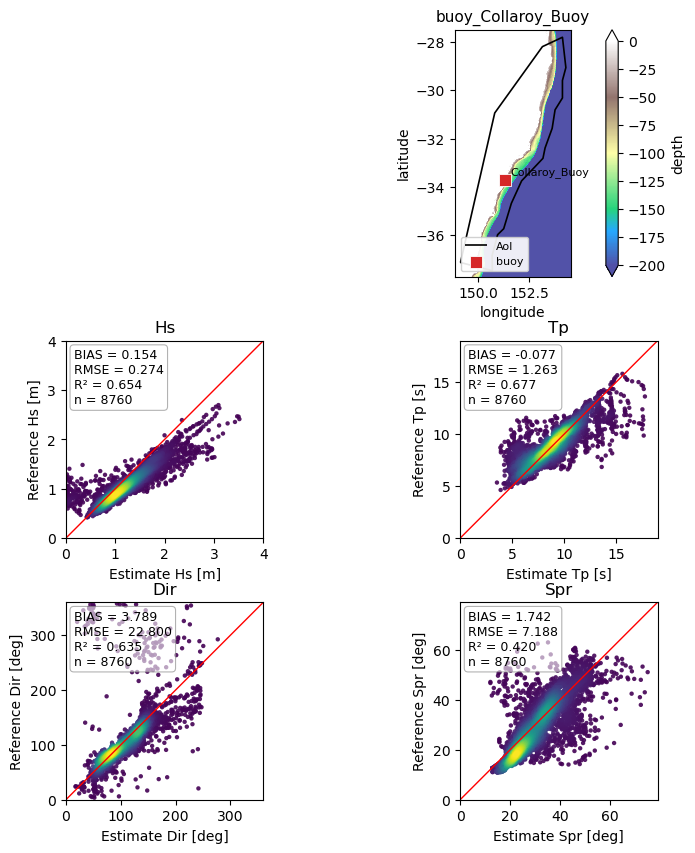

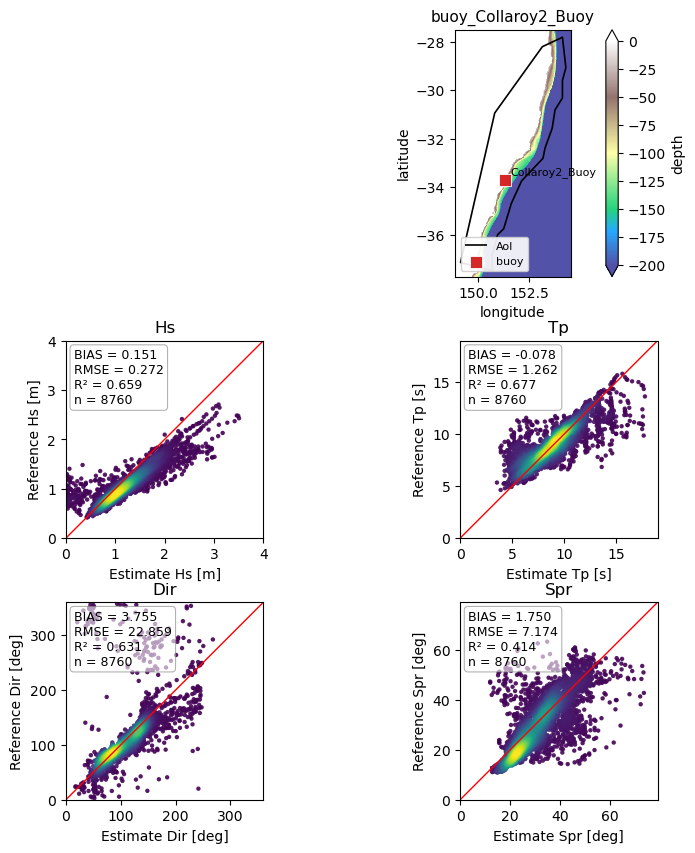

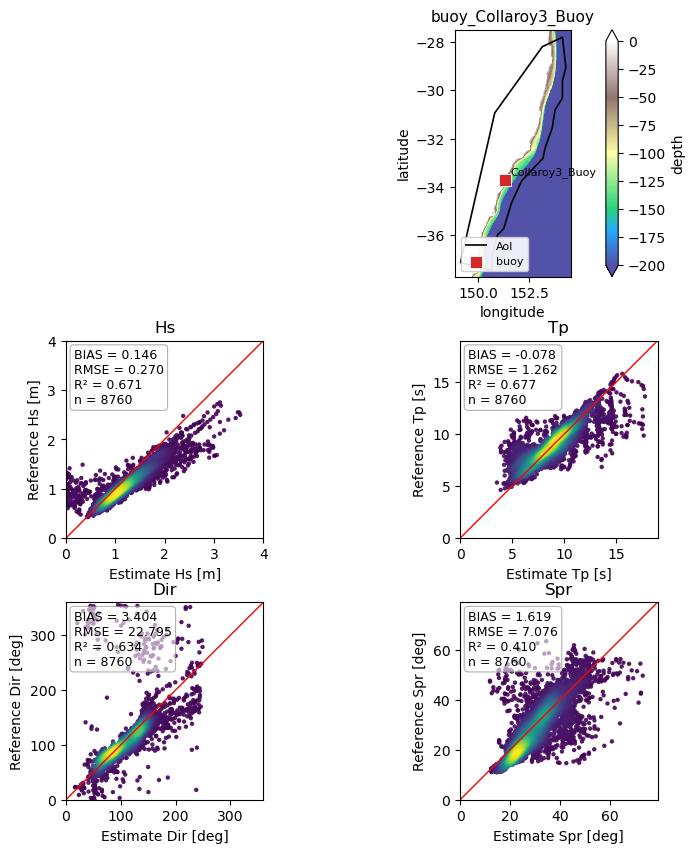

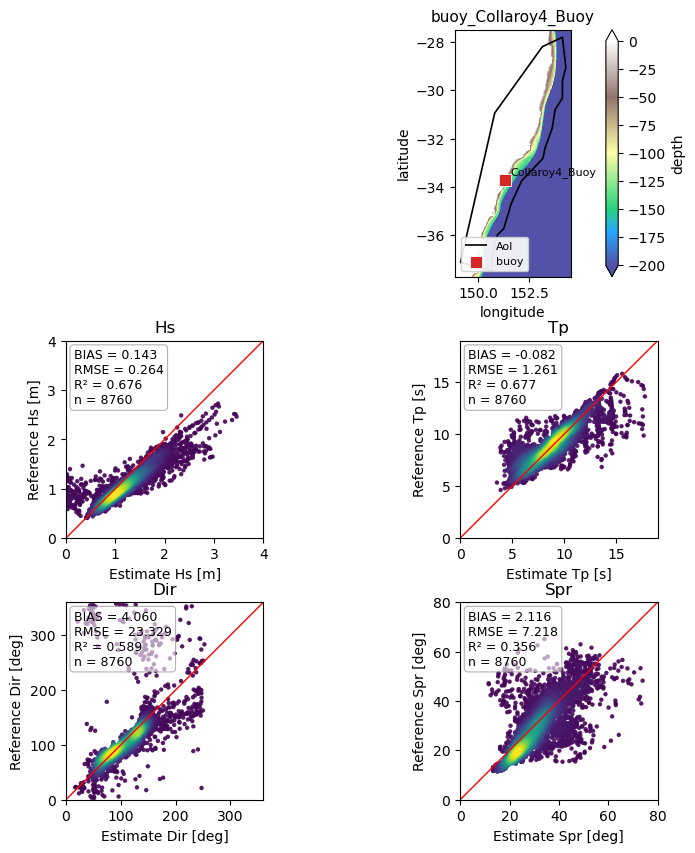

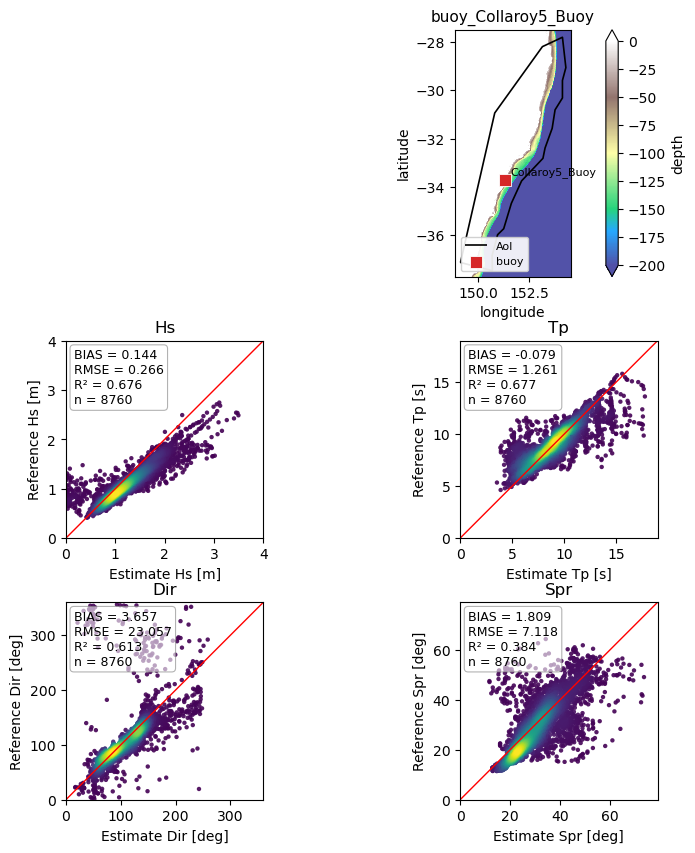

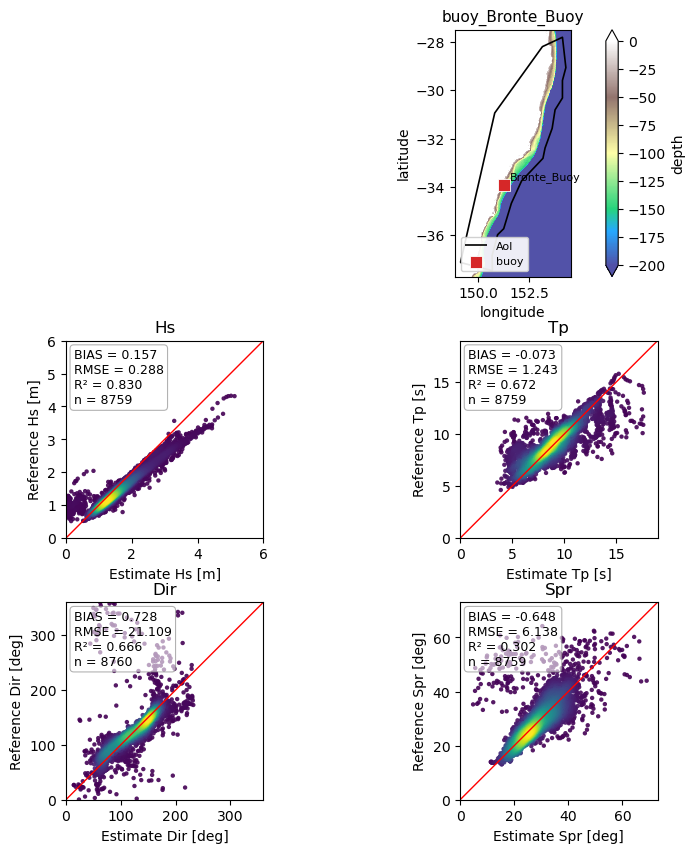

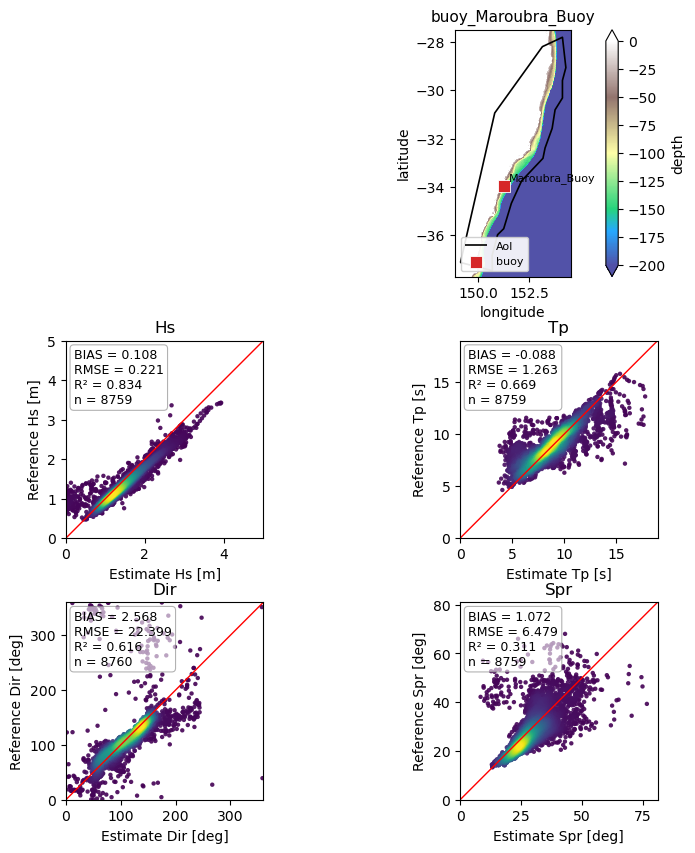

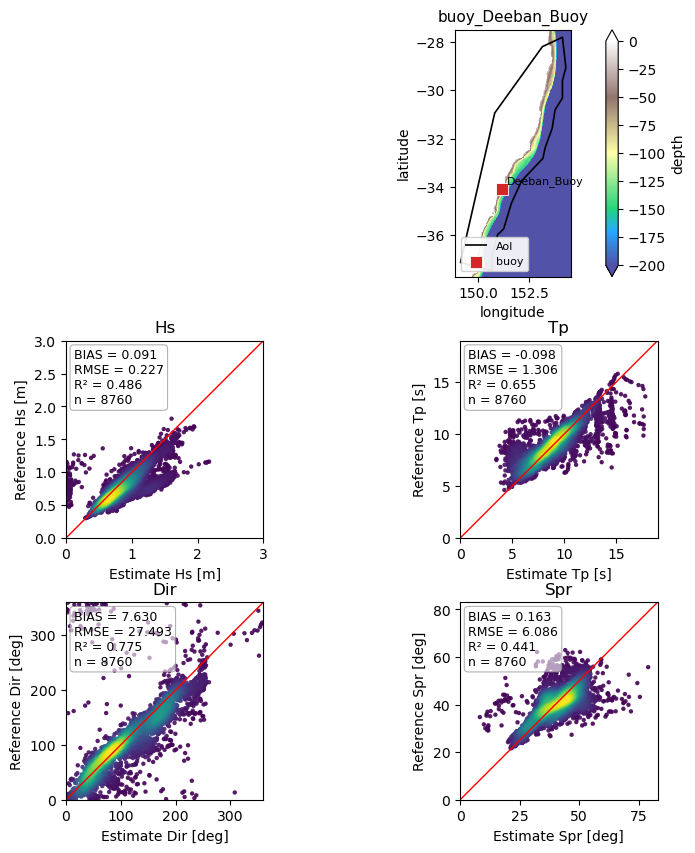

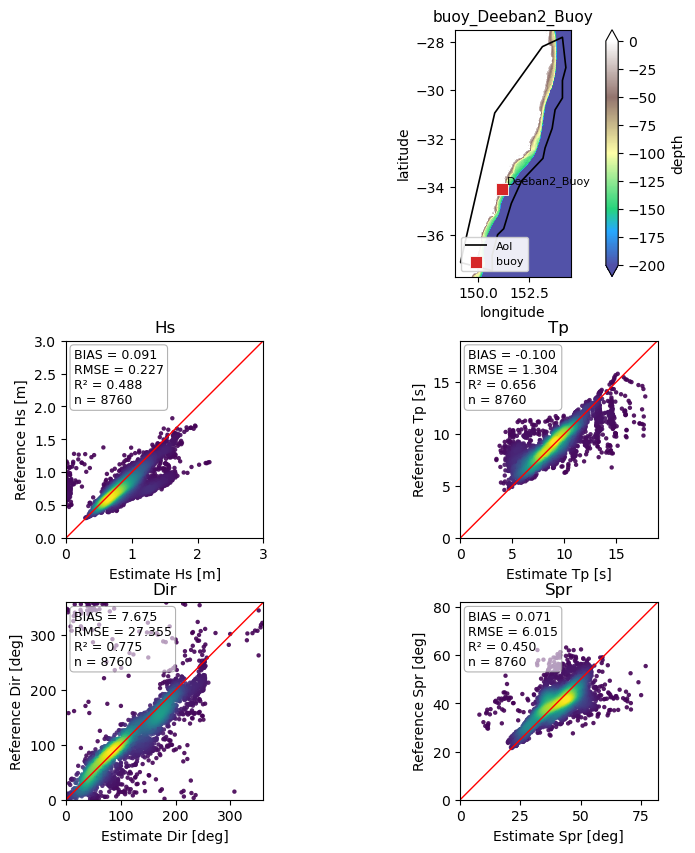

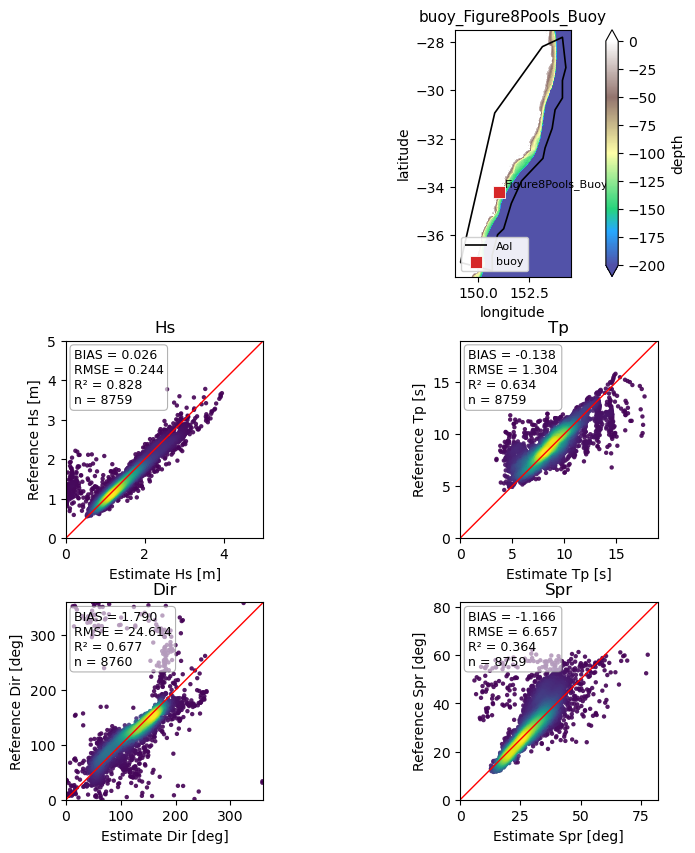

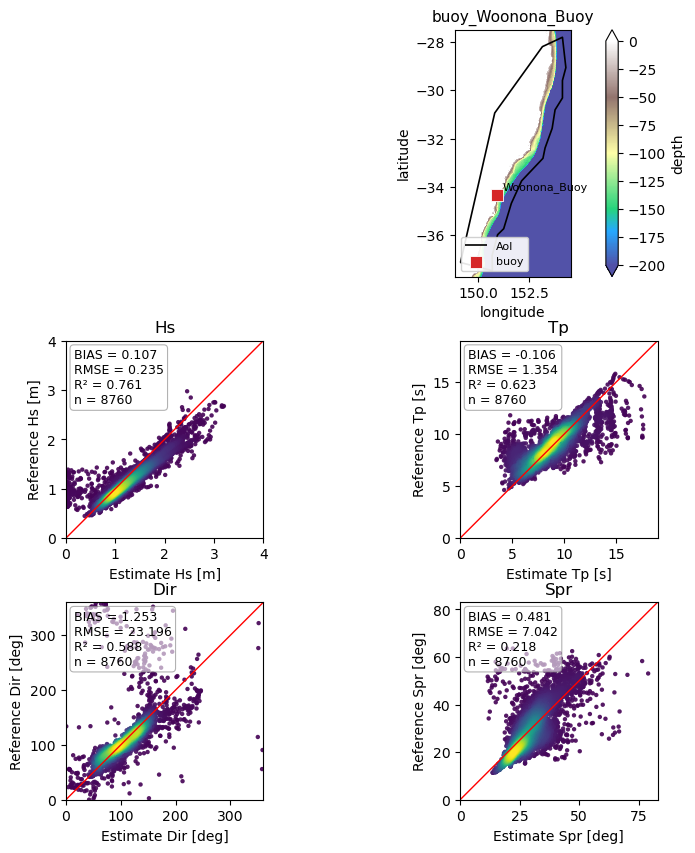

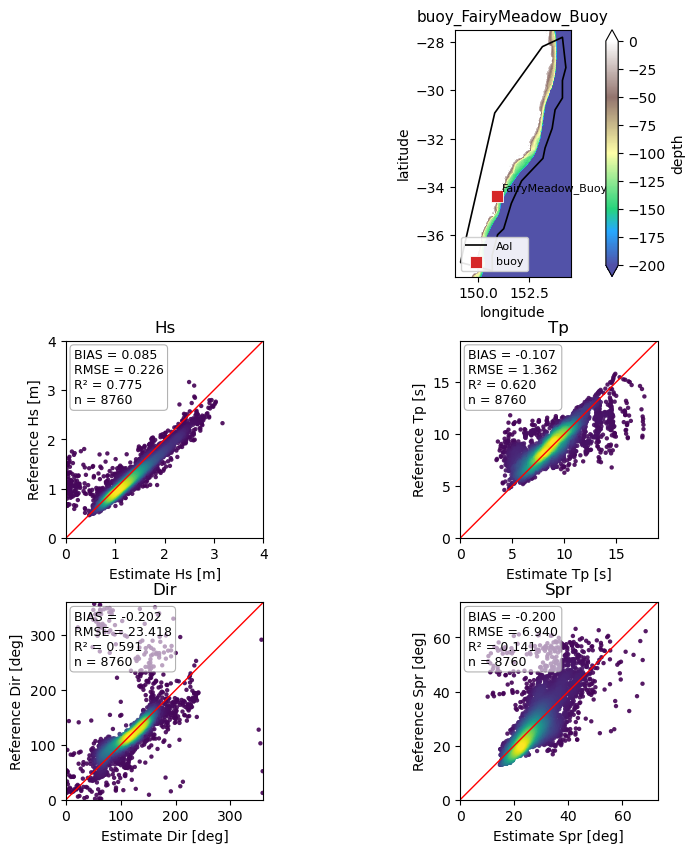

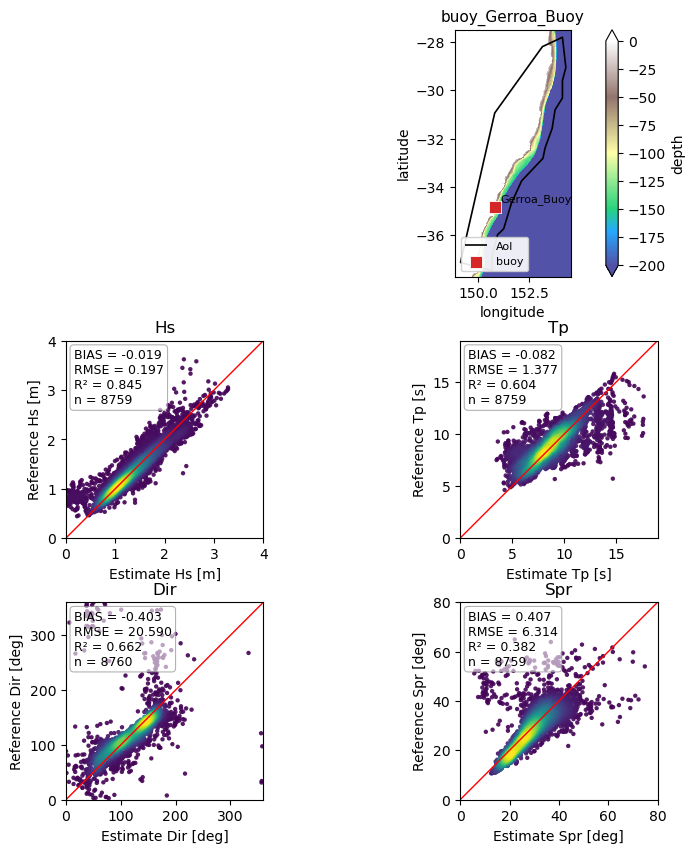

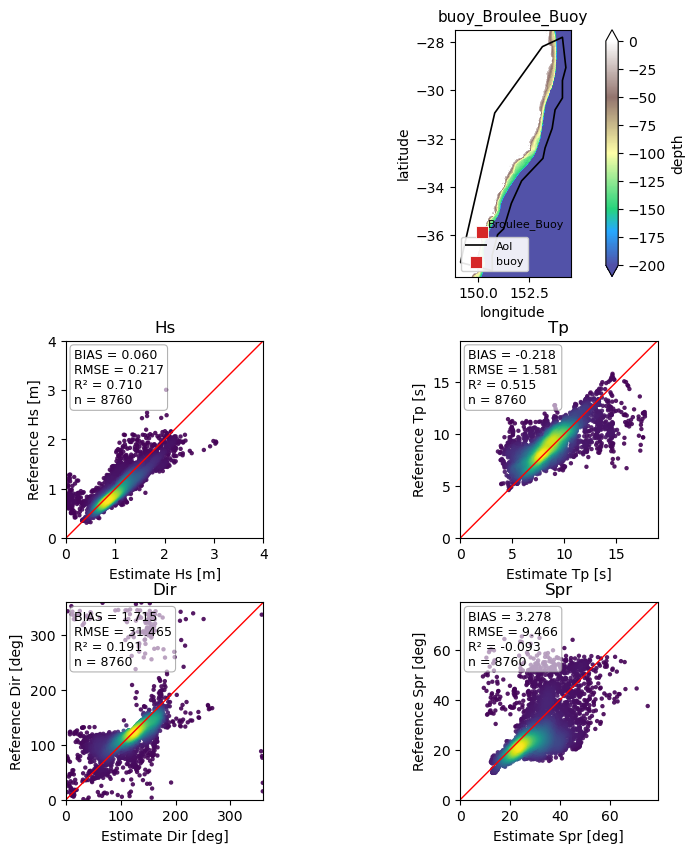

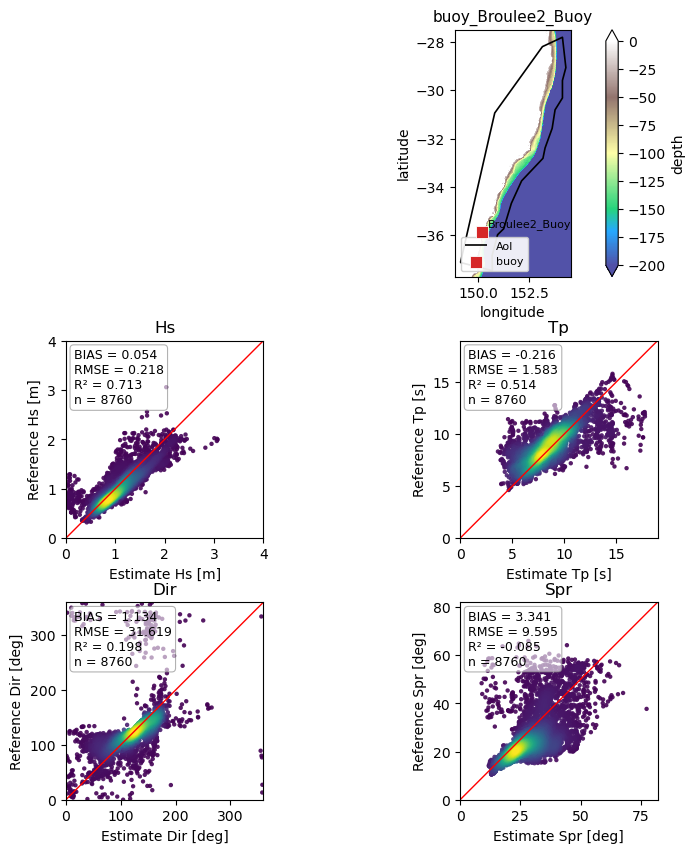

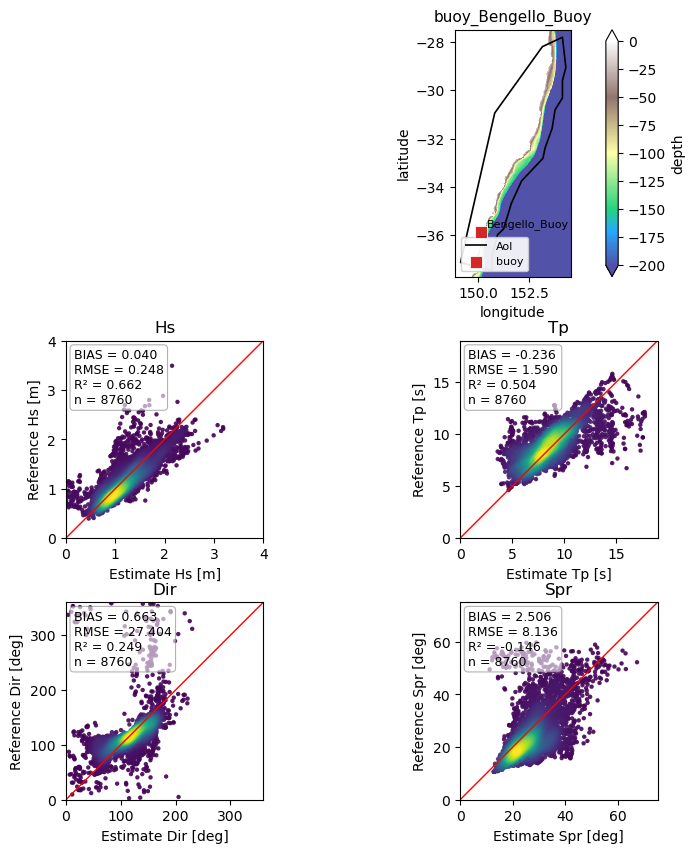

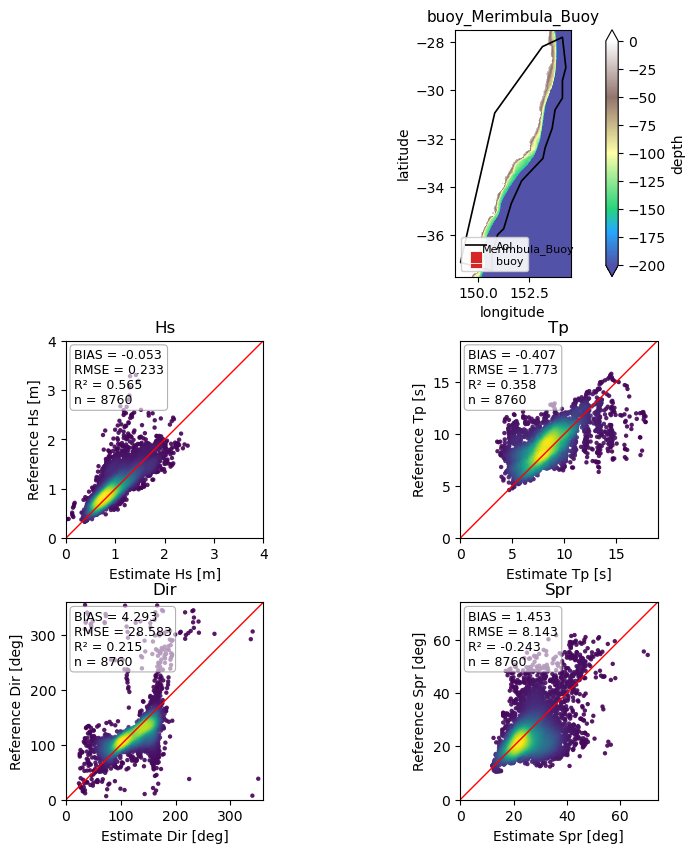

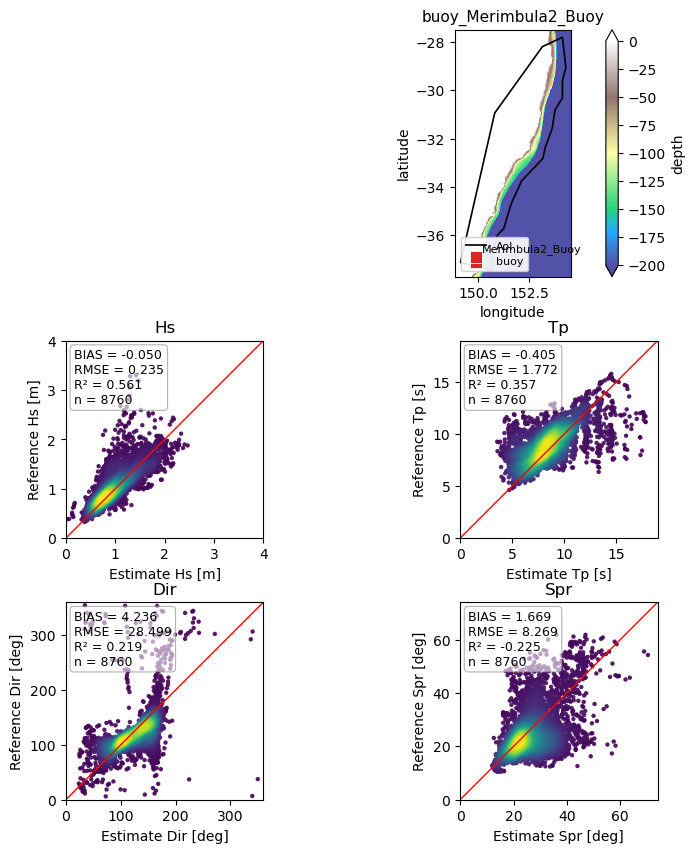

In [7]:
result.plot_all(variables=variables)
plt.show()